# 04 · Monitoreo — Detección de fraude (PaySim)

**Objetivo:** simular el monitoreo del modelo campeón en producción (steps 401–743) y detectar, por periodo:

| Tipo de drift | Qué se mide | Cómo |
|---|---|---|
| **Data drift** | ¿Cambió la distribución de las features? | Evidently: Wasserstein (numéricas) y Jensen-Shannon (categóricas/binarias), umbral 0.1 |
| **Prediction drift** | ¿Cambió la distribución del score y de las alertas? | Drift del score + tasa de predicciones positivas |
| **Concept drift** | ¿Cambió la relación features → target? | Tasa de fraude (prior), P(fraude \| vaciado total), % de fraudes que vacían la cuenta, drift del target |
| **Model drift** | ¿Se degradó el desempeño? | PR-AUC, recall, precision, F1, F2 por periodo (**métricas online**) vs test (**offline**) |

- **Referencia:** muestra uniforme de 100 K transacciones de steps ≤ 400 (`data/reference.csv`).
- **Producción:** todas las transacciones TRANSFER/CASH_OUT de steps ≥ 401 (`data/production.csv`).
- **Periodo:** 1 día simulado = 24 steps. Producción empieza en el step 401 (hora 16 del día 17), así que el primer
  periodo es parcial.

Los labels de producción se usan **solo** para calcular métricas online; el modelo no se reentrena.

In [1]:
import json
import os
import warnings

warnings.filterwarnings("ignore")  # before imports: silences tqdm/evidently import-time warnings

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd

from fraud_detection import config
from fraud_detection.interpret import load_champion
from fraud_detection.monitoring import (
    MODEL_FEATURES,
    RAW_COLUMNS,
    period_summary,
    period_table,
    run_report,
    save_snapshot,
    score,
)
from fraud_detection.plots import COLOR_FRAUD, COLOR_LEGIT, COLOR_NEUTRAL, finish, set_style
from fraud_detection.tracking import setup_mlflow

os.environ["MLFLOW_SUPPRESS_PRINTING_URL_TO_STDOUT"] = "true"
set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
pd.set_option("display.max_columns", 40)

model, meta = load_champion()
THRESHOLD = meta["threshold"]
reference = score(pd.read_csv(config.REFERENCE_SAMPLE_CSV), model, THRESHOLD)
production = score(pd.read_csv(config.PRODUCTION_CSV), model, THRESHOLD)

# Scored copies (raw columns + score) let the Streamlit app run without the model file.
for df, path in [(reference, config.REFERENCE_SCORED_CSV), (production, config.PRODUCTION_SCORED_CSV)]:
    df[RAW_COLUMNS + ["prediction"]].to_csv(path, index=False, float_format="%.6g")
    print(f"{path.relative_to(config.PROJECT_ROOT)}: {len(df):,} filas, {path.stat().st_size / 1e6:.1f} MB")

offline = pd.read_csv(config.TEST_RESULTS_CSV, index_col=0).loc[f"Modelo {meta['model_name']}"]
print(f"Modelo {meta['model_name']} v{meta['version']} | threshold {THRESHOLD:.4f}")
print("Métricas offline (test):", offline[["pr_auc", "precision", "recall", "f2"]].round(4).to_dict())

data/reference_scored.csv: 100,000 filas, 6.2 MB


data/production_scored.csv: 240,873 filas, 15.0 MB
Modelo xgboost v2 | threshold 0.8275
Métricas offline (test): {'pr_auc': 1.0, 'precision': 1.0, 'recall': 0.999, 'f2': 0.9992}


## 1. Periodos de producción

In [2]:
periods = period_table(production)
ref_rate = reference["isFraud"].mean()
print(f"Tasa de fraude en referencia: {ref_rate:.4%}")
periods

Tasa de fraude en referencia: 0.1590%


,period,step_min,step_max,transacciones,fraudes,tasa_fraude
0,17,401,408,86286,112,0.0013
1,18,409,432,8068,268,0.0332
2,19,433,456,4223,256,0.0606
3,20,457,480,8142,236,0.0290
4,21,481,504,10108,272,0.0269
5,22,505,528,21529,256,0.0119
6,23,529,552,20790,216,0.0104
7,24,553,576,13774,280,0.0203
8,25,577,600,24403,240,0.0098
9,26,601,624,5458,272,0.0498


## 2. Reportes Evidently por periodo

Para cada día se ejecuta un reporte con cuatro bloques: drift de features, drift del score, drift del target y
desempeño de clasificación. Cada snapshot se guarda comprimido en `reports/evidently/` (~200 KB), y la app de
Streamlit lo renderiza sin recalcular. El HTML completo de un reporte pesa ~4.6 MB; solo se exporta el de toda la
producción.

In [3]:
rows = []
for period in periods["period"]:
    current = production[production["period"] == period]
    snap = run_report(reference, current)
    save_snapshot(snap, config.EVIDENTLY_DIR / f"day_{period:02d}.json.gz")
    rows.append({"period": int(period), **period_summary(reference, current, THRESHOLD, snap)})

full_snap = run_report(reference, production)
save_snapshot(full_snap, config.EVIDENTLY_DIR / "production_all.json.gz")
full_snap.save_html(str(config.EVIDENTLY_DIR / "production_all.html"))

summary = periods.merge(pd.DataFrame(rows), on="period", suffixes=("", "_dup"))
summary = summary.drop(columns=[c for c in summary.columns if c.endswith("_dup")])
summary.to_csv(config.MONITORING_SUMMARY_CSV, index=False)
# Model card for the app: it must run from a clean clone, where models/ is git-ignored.
model_info = {
    "model_name": meta["model_name"], "registered_model": meta["registered_model"], "version": meta["version"],
    "alias": meta["alias"], "threshold": THRESHOLD, "reference_fraud_rate": float(reference["isFraud"].mean()),
    "offline_test": {k: float(offline[k]) for k in ["pr_auc", "precision", "recall", "f1", "f2"]},
}
config.MODEL_INFO_JSON.write_text(json.dumps(model_info, indent=2))
print(f"{len(rows)} reportes por periodo + 1 de toda la producción en {config.EVIDENTLY_DIR.relative_to(config.PROJECT_ROOT)}")
summary[["period", "transacciones", "fraudes", "features_drift_share", "drift_score__prediction",
         "drift_score__isFraud", "pr_auc", "recall", "precision"]]

15 reportes por periodo + 1 de toda la producción en reports/evidently


,period,transacciones,fraudes,features_drift_share,drift_score__prediction,drift_score__isFraud,pr_auc,recall,precision
0,17,86286,112,0.0667,0.0087,0.0027,1.0000,1.0000,1.0000
1,18,8068,268,0.3333,0.7812,0.0947,1.0000,0.9851,1.0000
2,19,4223,256,0.4000,1.4734,0.1353,1.0000,1.0000,1.0000
3,20,8142,236,0.2000,0.6843,0.0870,1.0000,1.0000,1.0000
4,21,10108,272,0.2000,0.6314,0.0830,1.0000,1.0000,1.0000
5,22,21529,256,0.2000,0.2567,0.0473,1.0000,1.0000,1.0000
6,23,20790,216,0.0667,0.2184,0.0426,1.0000,1.0000,1.0000
7,24,13774,280,0.2000,0.4671,0.0692,1.0000,1.0000,1.0000
8,25,24403,240,0.1333,0.2038,0.0408,1.0000,0.9958,1.0000
9,26,5458,272,0.4000,1.2042,0.1207,1.0000,1.0000,1.0000


## 3. Data drift

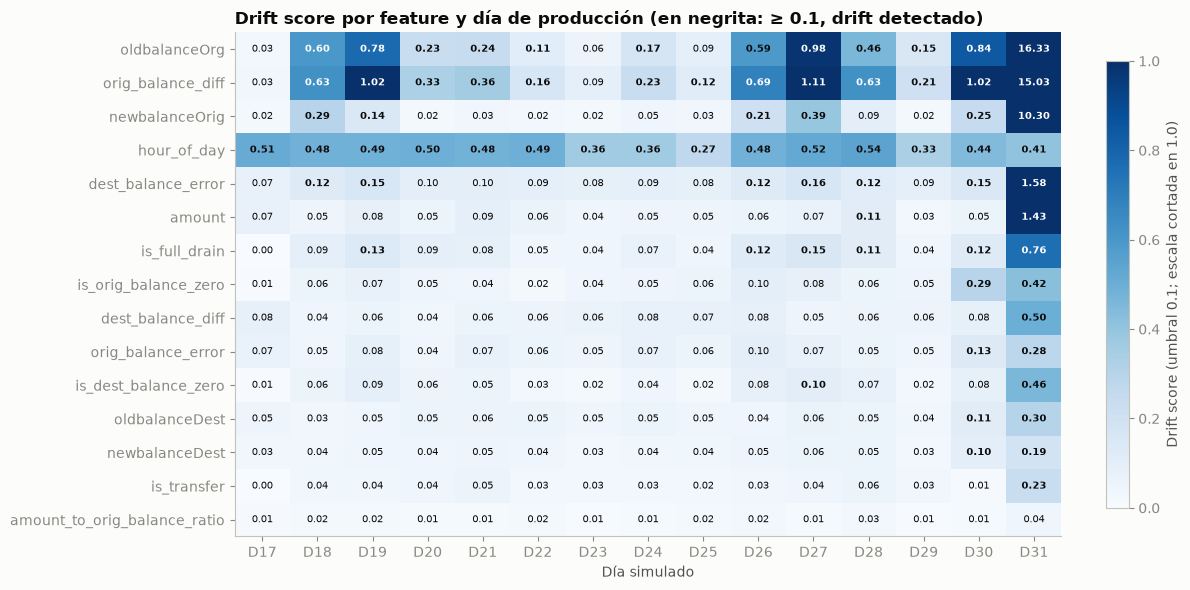

,% de días con drift,drift_score_medio
oldbalanceOrg,0.8000,1.4437
orig_balance_diff,0.8667,1.4427
newbalanceOrig,0.4000,0.7937
hour_of_day,1.0000,0.4447
dest_balance_error,0.4667,0.2065
amount,0.1333,0.1523
is_full_drain,0.4000,0.1267
is_orig_balance_zero,0.1333,0.0942
dest_balance_diff,0.0667,0.0917
orig_balance_error,0.1333,0.0822


In [4]:
drift_cols = [f"drift_score__{f}" for f in MODEL_FEATURES]
heat = summary.set_index("period")[drift_cols].T
heat.index = MODEL_FEATURES
heat = heat.loc[heat.mean(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(12, 6))
im = ax.imshow(heat.values, cmap="Blues", aspect="auto", vmin=0, vmax=1.0)  # day 31 (>10) saturates
ax.set_xticks(range(heat.shape[1]), [f"D{p}" for p in heat.columns])
ax.set_yticks(range(heat.shape[0]), heat.index)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                color="white" if v > 0.6 else "#0b0b0b", fontweight="bold" if v >= 0.1 else "normal")
ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.025, label="Drift score (umbral 0.1; escala cortada en 1.0)")
finish(ax, "Drift score por feature y día de producción (en negrita: ≥ 0.1, drift detectado)", "Día simulado", "")
fig.tight_layout()
plt.show()

drift_freq = (heat >= 0.1).mean(axis=1).rename("% de días con drift").to_frame()
drift_freq["drift_score_medio"] = heat.mean(axis=1)
drift_freq

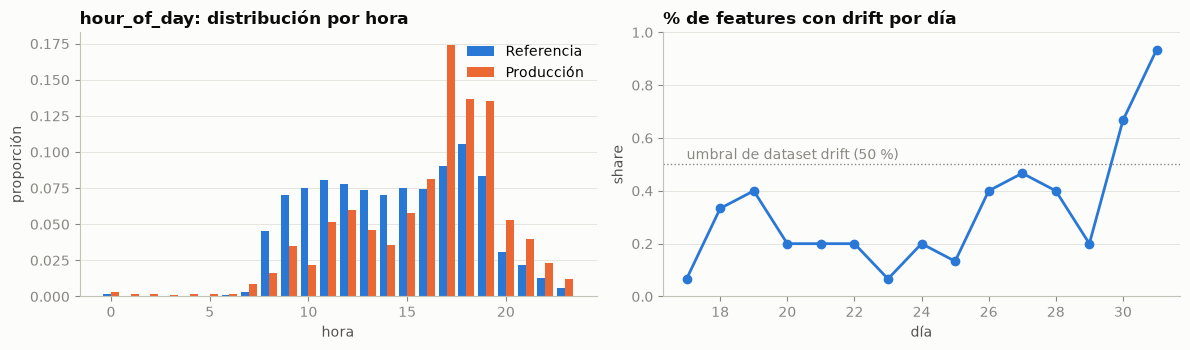

In [5]:
ref_hour = reference["hour_of_day"].value_counts(normalize=True).sort_index()
prod_hour = production["hour_of_day"].value_counts(normalize=True).sort_index()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].bar(ref_hour.index - 0.2, ref_hour.values, width=0.4, color=COLOR_LEGIT, label="Referencia")
axes[0].bar(prod_hour.index + 0.2, prod_hour.values, width=0.4, color=COLOR_FRAUD, label="Producción")
axes[0].legend()
finish(axes[0], "hour_of_day: distribución por hora", "hora", "proporción")
axes[1].plot(summary["period"], summary["features_drift_share"], color=COLOR_LEGIT, marker="o")
axes[1].axhline(0.5, color=COLOR_NEUTRAL, linestyle=":", linewidth=1)
axes[1].annotate("umbral de dataset drift (50 %)", (summary["period"].min(), 0.52), color=COLOR_NEUTRAL)
axes[1].set_ylim(0, 1)
finish(axes[1], "% de features con drift por día", "día", "share")
fig.tight_layout()
plt.show()

**Lectura: hay data drift fuerte y persistente, concentrado en pocas features.**
- **Saldos del origen**: `orig_balance_diff` deriva en el 87 % de los días, `oldbalanceOrg` en el 80 % y
  `newbalanceOrig` en el 40 %.
- **`hour_of_day`** deriva **todos** los días (Jensen-Shannon ≈ 0.4–0.5). Después del step 400 el volumen legítimo
  se desploma, así que en producción pesan mucho más las horas de madrugada (gráfico de horas).
- **Causa principal: prior shift.** En producción hay ~10× más fraude, y los fraudes mueven saldos grandes que se
  vacían; eso desplaza las distribuciones de saldo del origen. El ratio monto/saldo y el tipo de transacción
  casi no cambian.
- *Dataset drift* (> 50 % de features) solo en el día 30 (67 %) y el día 31 (93 %). El día 31 tiene **solo fraudes**
  (272 transacciones): la simulación deja de generar tráfico legítimo al final.
- El data drift indica que **la población cambió**, no necesariamente que el modelo empeoró (sección 5).

## 4. Prediction drift y concept drift

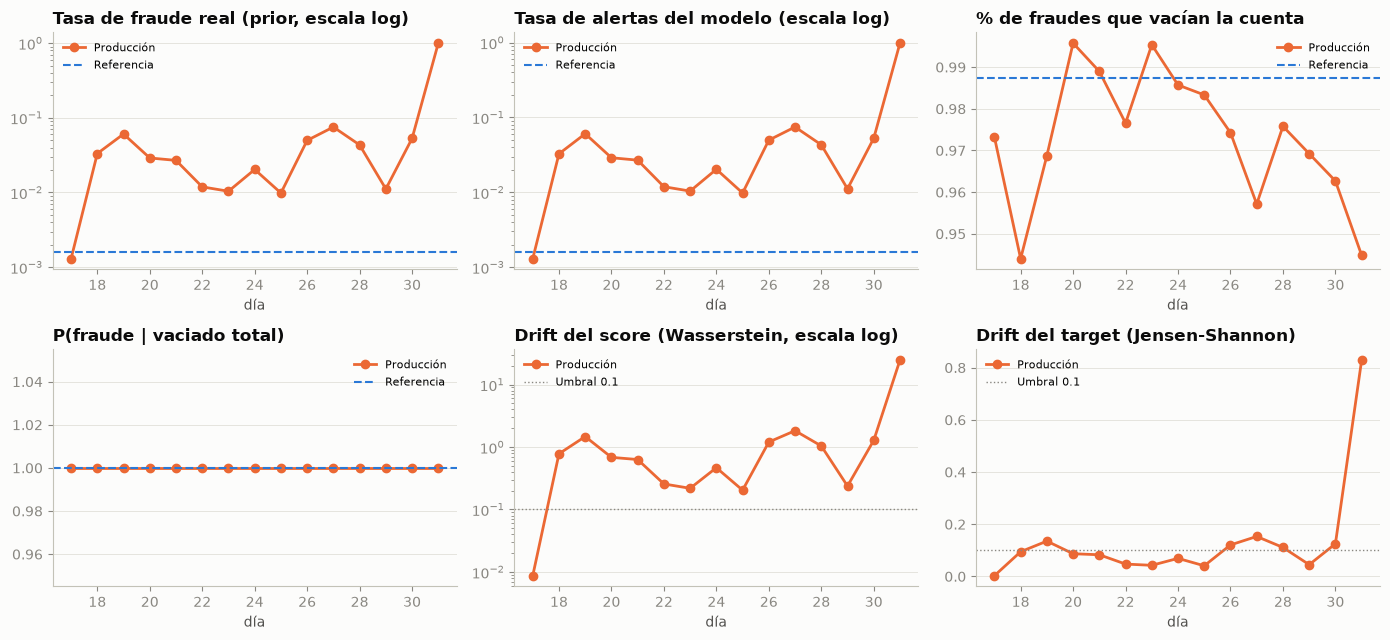

,referencia,producción (total)
fraud_rate,0.0016,0.0155
predicted_positive_rate,0.0016,0.0155
share_frauds_drain,0.9874,0.9724
p_fraud_given_drain,1.0000,1.0000


In [6]:
ref_concept = {
    "fraud_rate": ref_rate,
    "predicted_positive_rate": reference["prediction_label"].mean(),
    "share_frauds_drain": reference.loc[reference["isFraud"] == 1, "is_full_drain"].mean(),
    "p_fraud_given_drain": reference.loc[reference["is_full_drain"] == 1, "isFraud"].mean(),
}
panels = [  # (column, title, has reference line, log scale)
    ("fraud_rate", "Tasa de fraude real (prior, escala log)", True, True),
    ("predicted_positive_rate", "Tasa de alertas del modelo (escala log)", True, True),
    ("share_frauds_drain", "% de fraudes que vacían la cuenta", True, False),
    ("p_fraud_given_drain", "P(fraude | vaciado total)", True, False),
    ("drift_score__prediction", "Drift del score (Wasserstein, escala log)", False, True),
    ("drift_score__isFraud", "Drift del target (Jensen-Shannon)", False, False),
]
fig, axes = plt.subplots(2, 3, figsize=(14, 6.5))
for ax, (col, title, has_ref, log) in zip(axes.ravel(), panels, strict=True):
    ax.plot(summary["period"], summary[col], color=COLOR_FRAUD, marker="o", label="Producción")
    if has_ref:
        ax.axhline(ref_concept[col], color=COLOR_LEGIT, linestyle="--", linewidth=1.5, label="Referencia")
    else:
        ax.axhline(0.1, color=COLOR_NEUTRAL, linestyle=":", linewidth=1, label="Umbral 0.1")
    if log:
        ax.set_yscale("log")
    ax.legend(loc="best", fontsize=8)
    finish(ax, title, "día", "")
fig.tight_layout()
plt.show()
prod_concept = {
    "fraud_rate": production["isFraud"].mean(),
    "predicted_positive_rate": production["prediction_label"].mean(),
    "share_frauds_drain": production.loc[production["isFraud"] == 1, "is_full_drain"].mean(),
    "p_fraud_given_drain": production.loc[production["is_full_drain"] == 1, "isFraud"].mean(),
}
pd.DataFrame({"referencia": ref_concept, "producción (total)": prod_concept})

**Lectura: prior shift fuerte, sin concept drift.**
- **Prior shift**: la tasa de fraude pasa de 0.16 % (referencia) a **1.55 %** en producción (~10×), con días entre 0.1 %
  (día 17, parcial) y 7.5 %, y el caso extremo del día 31 (100 %). El drift del target supera 0.1 en los días 19, 26–28, 30 y 31.
- **Prediction drift**: el score cambia mucho (Wasserstein > 0.1 todos los días salvo el 17), pero la **tasa de
  alertas sigue exactamente a la tasa de fraude real** (1.55 % vs 1.55 %). El modelo no está inflando alertas: hay
  más fraude de verdad.
- **Relación features → target estable**: P(fraude | vaciado total) = **1.0 todos los días**, igual que en
  referencia, y el % de fraudes que vacían la cuenta se mantiene en 97.2 % (referencia 98.7 %).
- **Señal a vigilar**: ese % baja en los días 18, 27 y 31 (~94–96 %). Si el agente fraudulento dejara de vaciar
  cuentas, este sería el primer indicador en moverse.

Conclusión: es un escenario de **covariate shift + label shift** con el concepto intacto. Es el caso en que un modelo
bien especificado debería seguir funcionando.

## 5. Model drift: métricas online vs offline

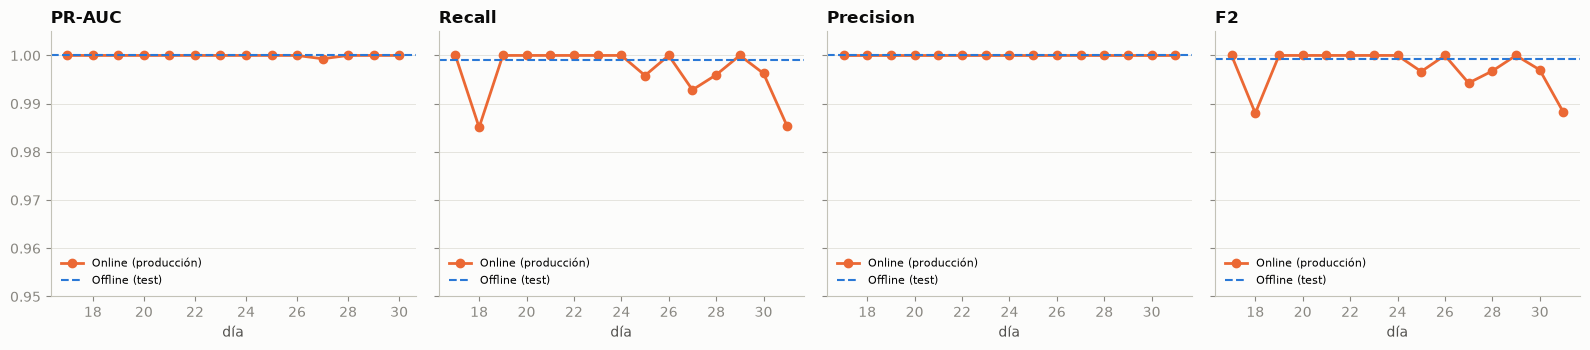

,offline (test),online (toda la producción),online peor día
precision,1.0000,1.0000,1.0000
recall,0.9990,0.9965,0.9851
f2,0.9992,0.9972,0.9880


,period,transacciones,fraudes,pr_auc,roc_auc,precision,recall,f1,f2,tp,fp,fn
0,17,86286,112,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,112,0,0
1,18,8068,268,1.0000,1.0000,1.0000,0.9851,0.9925,0.9880,264,0,4
2,19,4223,256,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,256,0,0
3,20,8142,236,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,236,0,0
4,21,10108,272,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,272,0,0
5,22,21529,256,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,256,0,0
6,23,20790,216,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,216,0,0
7,24,13774,280,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,280,0,0
8,25,24403,240,1.0000,1.0000,1.0000,0.9958,0.9979,0.9967,239,0,1
9,26,5458,272,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,272,0,0


In [7]:
metrics = [("pr_auc", "PR-AUC"), ("recall", "Recall"), ("precision", "Precision"), ("f2", "F2")]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
for ax, (col, title) in zip(axes, metrics, strict=True):
    ax.plot(summary["period"], summary[col], color=COLOR_FRAUD, marker="o", label="Online (producción)")
    ax.axhline(offline[col], color=COLOR_LEGIT, linestyle="--", linewidth=1.5, label="Offline (test)")
    ax.set_ylim(0.95, 1.005)
    ax.legend(loc="lower left", fontsize=8)
    finish(ax, title, "día", "")
fig.tight_layout()
plt.show()

total = summary[["tp", "fp", "fn", "tn"]].sum()
online_total = {
    "precision": total["tp"] / (total["tp"] + total["fp"]),
    "recall": total["tp"] / (total["tp"] + total["fn"]),
}
online_total["f2"] = 5 * online_total["precision"] * online_total["recall"] / (
    4 * online_total["precision"] + online_total["recall"])
comparison = pd.DataFrame({
    "offline (test)": offline[["precision", "recall", "f2"]].astype(float),
    "online (toda la producción)": pd.Series(online_total),
    "online peor día": summary[["precision", "recall", "f2"]].min(),
})
display(comparison)
summary[["period", "transacciones", "fraudes", "pr_auc", "roc_auc", "precision", "recall", "f1", "f2", "tp", "fp", "fn"]]

**Lectura: no hay model drift.**
- **Precision = 1.0 todos los días**: ni una falsa alarma en 240,873 transacciones de producción.
- **Recall online diario entre 98.5 % y 100 %**. En toda la producción: **99.65 %** (3,723 de 3,736 fraudes) frente a
  99.9 % offline. F2 0.997 vs 0.999.
- PR-AUC ≈ 1 en todos los días con ambas clases (el día 31 no la tiene definida: una sola clase).
- Los 13 fraudes perdidos se concentran en los días 18 y 31 (4 cada uno), justo los días con menor % de fraudes que
  vacían la cuenta. El indicador de concepto **anticipa** la caída de recall y sirve como alerta temprana.
- **Lección de monitoreo:** el data drift y el prediction drift fueron fuertes y, sin embargo, el desempeño no se
  degradó. Alertar solo por drift habría producido falsas alarmas operativas. Hace falta combinarlo con
  métricas online (cuando llegan los labels) e indicadores de concepto.

## 6. Registro en MLflow

Un run `production-monitoring` en el experimento `paysim-fraud-monitoring`, con cada indicador registrado **por
paso = día** (MLflow grafica su evolución), la tabla resumen y el reporte HTML completo de Evidently.

In [8]:
setup_mlflow(config.MLFLOW_EXPERIMENT_MONITORING)
step_metrics = ["features_drift_share", "drift_score__prediction", "drift_score__isFraud", "fraud_rate",
                "predicted_positive_rate", "share_frauds_drain", "pr_auc", "recall", "precision", "f2"]
with mlflow.start_run(run_name="production-monitoring") as run:
    mlflow.set_tags({"stage": "monitoring", "model": meta["model_name"], "champion_run_id": meta["mlflow_run_id"]})
    mlflow.log_params({"registered_model": meta["registered_model"], "version": meta["version"],
                       "threshold": THRESHOLD, "period_steps": config.PERIOD_STEPS,
                       "reference_rows": len(reference), "production_rows": len(production)})
    for r in summary.itertuples():
        mlflow.log_metrics({m: float(getattr(r, m)) for m in step_metrics if pd.notna(getattr(r, m))}, step=int(r.period))
    mlflow.log_metrics({f"online_total_{k}": float(v) for k, v in online_total.items()})
    mlflow.log_table(summary, "tables/monitoring_summary.json")
    mlflow.log_artifact(str(config.EVIDENTLY_DIR / "production_all.html"), "evidently")
print(f"Run de monitoreo: {run.info.run_id}")

Run de monitoreo: 907819f01ca142588d955630c1e0b023


## 7. Conclusiones y política de alertas propuesta

| Indicador | Umbral de alerta | Acción |
|---|---|---|
| Recall online diario | < 0.98 | Investigar los fraudes perdidos; evaluar reentrenamiento |
| Precision online diaria | < 0.99 | Revisar el threshold (capacidad del equipo de revisión) |
| % de fraudes que vacían la cuenta | < 0.95 | **Alerta temprana** de cambio de táctica del fraude |
| P(fraude \| vaciado total) | < 0.99 | Concept drift en la señal principal → reentrenar |
| Tasa de fraude / alertas | > 10× referencia | Avisar a operaciones (volumen de revisiones) |
| Dataset drift (share de features) | > 50 % | Informativo: revisar calidad de datos y cambios de población |

- En estos 15 días **no se dispara ninguna alerta de desempeño**. El modelo es estable pese a un prior shift de ~10×
  y a drift fuerte en saldos y horario.
- **Limitación real:** aquí los labels de producción están disponibles de inmediato. En un banco, la confirmación de
  fraude llega con días o semanas de retraso, así que los indicadores sin label (drift, tasa de alertas, % de
  vaciados entre las alertas) serían la primera línea de defensa.
- Los reportes Evidently de cada día están en `reports/evidently/` y se exploran en la app
  (`streamlit run app/app.py`), que también simula el flujo de transacciones en tiempo real.